# Gaussian process classification on Iris

Isotropic and anisotropic RBF kernels fit the three Iris classes using sepal length and width. The anisotropic kernel learns a separate length scale for each feature.

The [scikit-learn gallery source](https://github.com/scikit-learn/scikit-learn/blob/4358542a1bd39af2e7e1cbace8b9fed067473c5b/examples/gaussian_process/plot_gpc_iris.py)
is by the scikit-learn developers and licensed under BSD-3-Clause. See
[Gaussian process license notices](../../LICENSES/gaussian-process-NOTICES).

Python supplies the shared inputs, executes the pinned scikit-learn reference, compares results and draws both sets of plots. Moxie fits and predicts in native Mojo.

In [1]:
import runpy
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("gaussian_process/plot_gpc_iris")

reference = runpy.run_path(str(ROOT / "tests/gaussian_process/classification/parity.py"))
Classifier, kernels = reference["pinned_classifier"]()

## Fit the pinned scikit-learn model

In [2]:
iris_file = reference["REFERENCE"] / "sklearn/datasets/data/iris.csv"
iris = np.loadtxt(iris_file, delimiter=",", skiprows=1)
X, y = iris[:, :2], iris[:, -1].astype(np.int64)
xx, yy = np.meshgrid(*(np.linspace(lo - 1, hi + 1, 100)
                       for lo, hi in zip(X.min(axis=0), X.max(axis=0))))
titles = ("Isotropic RBF", "Anisotropic RBF")
configured_kernels = (1.0 * kernels.RBF([1.0]), 1.0 * kernels.RBF([1.0, 1.0]))
fit_options = {}

query = np.column_stack((xx.ravel(), yy.ravel()))
nb.share(X=X, y=y, query=query)
expected = []
for kernel in configured_kernels:
    model = Classifier(kernel=kernel, **fit_options).fit(X, y)
    expected.append(dict(
        classes=model.classes_,
        predictions=model.predict(query),
        probabilities=model.predict_proba(query),
        theta=model.kernel_.theta,
        lml=model.log_marginal_likelihood(model.kernel_.theta),
        score=model.score(X, y),
    ))

## Fit the native Mojo model

Labels are Int64 arrays. Fitted kernel metadata is available through `kernel_()`. Pass a typed `List[Float64]` to select the anisotropic RBF constructor.

In [3]:
%%mojo classification
from moxie.gaussian_process import GaussianProcessClassifier
from moxie.gaussian_process.kernels import Kernel, RBF
from moxie_nb_io import load, save, save_floats


def main() raises:
    var X = load("X")
    var y = load[DType.int64]("y")
    var query = load("query")
    var length_scales: List[Float64] = [1.0, 1.0]
    var configured_kernels: List[Kernel] = [1.0 * RBF(1.0), 1.0 * RBF(length_scales)]
    for i in range(len(configured_kernels)):
        var suffix = String(i)
        var model = GaussianProcessClassifier(configured_kernels[i])
        _ = model.fit(X, y)
        var theta = model.kernel_().theta()
        save("classes_" + suffix, model.classes_())
        save("predictions_" + suffix, model.predict(query))
        save("probabilities_" + suffix, model.predict_proba(query))
        save("theta_" + suffix, theta)
        save_floats("lml_" + suffix, [model.log_marginal_likelihood(theta^).value])
        save_floats("score_" + suffix, [model.score(X, y)])

## Compare fitted results

The checks cover the full query grid and require exact agreement for sorted classes, predictions and training accuracy.

In [4]:
native = nb.results["classification"]
actual = []
exact = {"classes", "predictions", "score"}
for i, (title, reference_result) in enumerate(zip(titles, expected, strict=True)):
    result = {key: native[f"{key}_{i}"] for key in reference_result}
    for key in ("lml", "score"):
        result[key] = result[key].item()
    actual.append(result)
    for key, expected_value in reference_result.items():
        assert np.asarray(result[key]).dtype == np.asarray(expected_value).dtype, (title, key)
        nb.compare(
            f"{title} · {key}", expected_value, result[key], exact=key in exact,
            rtol=1e-6, atol=1e-7,
            reason="" if key in exact else
            "Allows for differences in Float64 reduction order and optimizer stopping points.",
        )

nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
Isotropic RBF · classes,PASS,"(3,)","(3,)",,,exact,0 mismatches,
Isotropic RBF · predictions,PASS,"(10000,)","(10000,)",,,exact,0 mismatches,
Isotropic RBF · probabilities,PASS,"(10000, 3)","(10000, 3)",2.76e-10,1.24e-09,"rtol=1e-06, atol=1e-07",,Allows for differences in Float64 reduction order and optimizer stopping points.
Isotropic RBF · theta,PASS,"(6,)","(6,)",2.22e-12,5.05e-13,"rtol=1e-06, atol=1e-07",,Allows for differences in Float64 reduction order and optimizer stopping points.
Isotropic RBF · lml,PASS,(),(),4.69e-13,9.71e-15,"rtol=1e-06, atol=1e-07",,Allows for differences in Float64 reduction order and optimizer stopping points.
Isotropic RBF · score,PASS,(),(),,,exact,0 mismatches,
Anisotropic RBF · classes,PASS,"(3,)","(3,)",,,exact,0 mismatches,
Anisotropic RBF · predictions,PASS,"(10000,)","(10000,)",,,exact,0 mismatches,
Anisotropic RBF · probabilities,PASS,"(10000, 3)","(10000, 3)",2.58e-10,2.16e-09,"rtol=1e-06, atol=1e-07",,Allows for differences in Float64 reduction order and optimizer stopping points.
Anisotropic RBF · theta,PASS,"(9,)","(9,)",1.25e-09,1.37e-09,"rtol=1e-06, atol=1e-07",,Allows for differences in Float64 reduction order and optimizer stopping points.


## Probability surfaces

Hue identifies the most probable class. Opacity shows its probability.

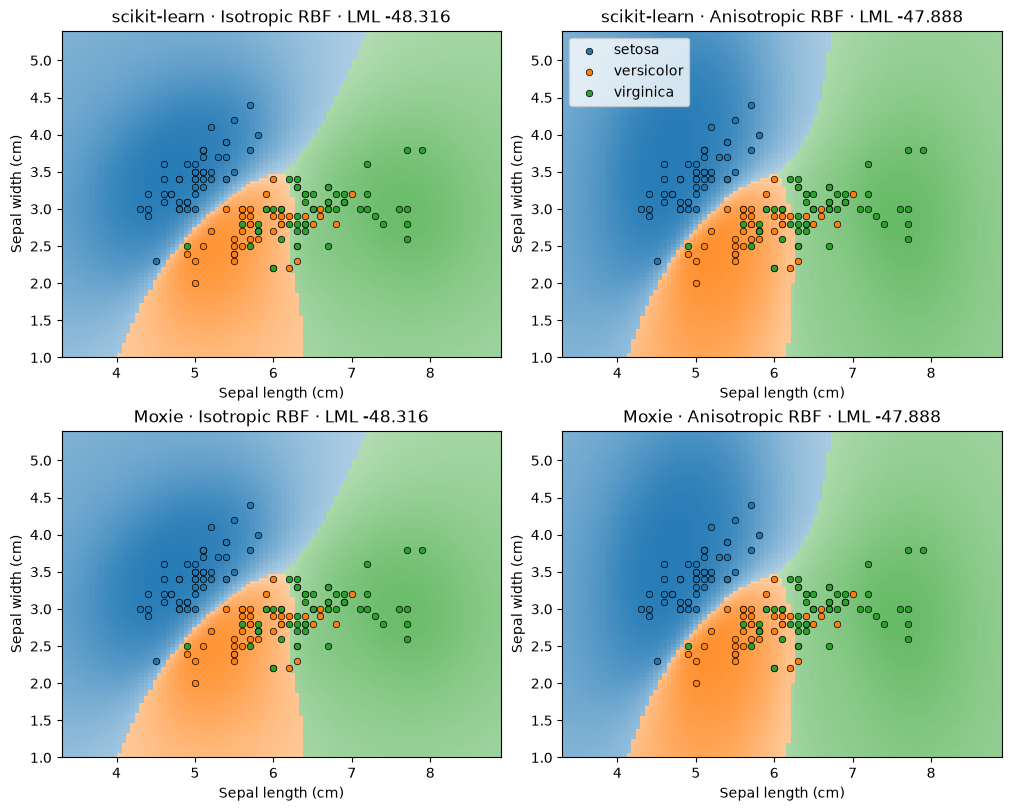

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout="constrained")
for row, (backend, results) in enumerate((("scikit-learn", expected), ("Moxie", actual))):
    for col, (title, result) in enumerate(zip(titles, results, strict=True)):
        ax = axes[row, col]
        probabilities = result["probabilities"]
        colors = plt.get_cmap("tab10")(np.arange(len(result["classes"])))
        winner = probabilities.argmax(axis=1)
        rgba = colors[winner]
        rgba[:, 3] = probabilities[np.arange(len(winner)), winner]
        ax.pcolormesh(xx, yy, rgba.reshape(*xx.shape, 4), shading="auto")
        for label, color, species in zip(result["classes"], colors, ("setosa", "versicolor", "virginica"), strict=True):
            ax.scatter(*X[y == label].T, color=color, label=species,
                       edgecolors="black", linewidths=0.5, s=22)
        ax.set(xlabel="Sepal length (cm)", ylabel="Sepal width (cm)")
        if row == 0 and col == 1:
            ax.legend(loc="upper left")
        ax.set_title(f"{backend} · {title} · LML {result['lml']:.3f}")
        ax.set(xlim=(xx.min(), xx.max()), ylim=(yy.min(), yy.max()))
plt.show()